# TEM nanoparticle polydispersity

Automatically measures the diameter of spherical nanoparticles in Bright Field TEM images (packed particles, possibly touching each other) and computes polydispersity statistics (mean, standard deviation, CV%, PDI).

**Pipeline**
1. Pixel -> nm calibration via the black scale bar present in the image.
2. Thresholding (Otsu) to separate particles (dark) from background (light).
3. Watershed segmentation (based on the distance transform) to separate particles that are touching each other.
4. Measurement of area/equivalent diameter/circularity for each particle, filtering out fragments that are too small or not circular enough (noise).
5. Computation of polydispersity statistics + histogram + verification overlay.

**Dependencies**: `opencv-python-headless`, `numpy`, `scipy`, `scikit-image`, `matplotlib` (see `requirements.txt`).

## Configuration

Set the path to your TEM image (and, if needed, the other parameters) here before running the rest of the notebook.

**Note on `scalebar_nm`**: the code auto-detects the scale bar's length in *pixels* by scanning the image, but it cannot read the nm value printed next to it (that's text, not something the code OCRs) — you must set it here to match what's written on your image. If different images in your dataset have different scale bar values, update `scalebar_nm` accordingly before re-running.

**`.emd` files (Thermo Fisher Velox)** don't need `nm` at all — calibration and bright-/dark-field mode are read automatically from the file's own metadata; `nm` is simply ignored for those.

In [1]:
import os

import cv2
import numpy as np
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.measure import regionprops
import hyperspy.api as hs
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
image_path = "./Data/Velox/STEM HAADF 1356.emd"  # <-- set the path to your TEM image
scalebar_region = (0.85, 1.0, 0.0, 0.35)
outdir = "Result_Poly"

In [3]:
nm = 100  # <-- must match the nm value printed on the scale bar (ignored for .emd files, whose calibration comes from metadata)

## 1. Scale bar calibration

In [4]:
def calibrate_scalebar(gray_img, scalebar_nm=nm, region=(0.85, 1.0, 0.0, 0.35),
                        dark_thresh=100, min_bar_px=30):
    """
    Finds the length in pixels of the scale bar (solid, horizontal black
    bar) within a sub-region of the image and computes the nm/pixel
    conversion factor.

    Parameters
    ----------
    gray_img : np.ndarray (2D, uint8)
        Grayscale image.
    scalebar_nm : float
        Real length of the scale bar in nm (e.g. 200). This value is NOT
        detected automatically -- it must match the text printed on the
        image, since this function does not perform OCR.
    region : tuple(float, float, float, float)
        Fractions (row_start, row_end, col_start, col_end) of the image
        region in which to search for the scale bar. Default: bottom-left
        corner.
    dark_thresh : int
        Intensity threshold below which a pixel is considered "black"
        (part of the scale bar).
    min_bar_px : int
        Minimum number of consecutive dark pixels in a row for it to be
        considered a scale bar row (avoids confusing the "200 nm" text
        with the bar itself).

    Returns
    -------
    dict with:
        nm_per_px : float
        bar_length_px : float (auto-detected from the image)
        bar_bbox : (row, col_start, col_end) in the original image coordinates
    """
    h, w = gray_img.shape
    r0, r1, c0, c1 = region
    r0, r1 = int(h * r0), int(h * r1)
    c0, c1 = int(w * c0), int(w * c1)
    crop = gray_img[r0:r1, c0:c1]

    dark_mask = crop < dark_thresh

    best_row, best_start, best_end, best_len = None, None, None, 0
    for row in range(dark_mask.shape[0]):
        cols = np.where(dark_mask[row])[0]
        if len(cols) < min_bar_px:
            continue
        # the bar is a continuous segment: take min/max and check that
        # most pixels in that range are actually dark
        # (to exclude text rows, which are more "sparse")
        span = cols.max() - cols.min() + 1
        if span < min_bar_px:
            continue
        fill_ratio = len(cols) / span
        if fill_ratio > 0.9 and span > best_len:
            best_row, best_start, best_end, best_len = row, cols.min(), cols.max(), span

    if best_row is None:
        raise RuntimeError(
            "Scale bar not found automatically: try changing 'region' "
            "or 'dark_thresh'."
        )

    bar_length_px = best_end - best_start + 1
    nm_per_px = scalebar_nm / bar_length_px

    return {
        "nm_per_px": nm_per_px,
        "bar_length_px": bar_length_px,
        "bar_bbox": (best_row + r0, best_start + c0, best_end + c0),
    }

## 1b. Format-aware image loading (scale bar images or Thermo Fisher .emd)

`load_image()` picks the right calibration source depending on the file:
- **`.emd`** (Thermo Fisher Velox): pixel size and acquisition mode (bright-field vs dark-field/HAADF) are read directly from the file's metadata via HyperSpy — no scale bar needed. The raw detector counts are rescaled to 8-bit for the segmentation step below.
- **other formats** (jpg/png/tif/...): calibration comes from the scale bar drawn on the image (`calibrate_scalebar`, above), and bright-field is assumed.

For dark-field/HAADF images the particles are the *brightest* pixels rather than the darkest, so segmentation (next section) needs to know which case it's in — that's what `is_darkfield` is for.

In [5]:
UNIT_TO_NM = {
    "nm": 1.0,
    "um": 1000.0,
    "µm": 1000.0,
    "pm": 0.001,
    "a": 0.1,
    "å": 0.1,
    "angstrom": 0.1,
    "m": 1e9,
}


def normalize_to_uint8(data, low_percentile=1.0, high_percentile=99.0):
    """
    Rescales an arbitrary-range array (e.g. raw STEM detector counts) to
    0-255 uint8, clipping the extreme percentiles first so a few outlier
    pixels don't compress the contrast of the rest of the image.
    """
    lo, hi = np.percentile(data, [low_percentile, high_percentile])
    if hi <= lo:
        lo, hi = float(data.min()), float(data.max())
    clipped = np.clip(data, lo, hi)
    scaled = (clipped - lo) / (hi - lo + 1e-12) * 255.0
    return scaled.astype(np.uint8)


def classify_darkfield(detector_name):
    """
    Guesses bright-field vs dark-field from a Thermo Fisher detector name
    (e.g. 'HAADF', 'DF-S' -> dark-field; 'BF-S' -> bright-field). Defaults
    to bright-field (False) if the name is missing or unrecognized.
    """
    if not detector_name:
        return False
    return "DF" in str(detector_name).upper()


def load_emd_image(path, signal_index=0):
    """
    Loads a Thermo Fisher Velox .emd file with HyperSpy and returns
    (gray_uint8, nm_per_px, is_darkfield, info). Calibration and
    acquisition mode are read from the file's metadata -- no scale bar
    detection needed. If the file contains multiple signals, the one at
    signal_index is used (default: the first).
    """
    result = hs.load(path)
    signals = result if isinstance(result, list) else [result]
    if len(signals) > 1:
        print("Note: " + str(len(signals)) + " signals found in '" + path +
              "', using index " + str(signal_index) +
              " (" + str(signals[signal_index].metadata.General.title) + ")")
    s = signals[signal_index]

    ax = s.axes_manager.signal_axes[0]
    unit_factor = UNIT_TO_NM.get(str(ax.units).lower(), 1.0)
    nm_per_px = float(ax.scale) * unit_factor

    om = s.original_metadata.as_dictionary()
    detector_name = om.get("BinaryResult", {}).get("Detector") or s.metadata.General.title
    is_darkfield = classify_darkfield(detector_name)

    gray = normalize_to_uint8(s.data)

    info = {
        "detector": detector_name,
        "raw_dtype": str(s.data.dtype),
        "raw_min": float(s.data.min()),
        "raw_max": float(s.data.max()),
    }
    return gray, nm_per_px, is_darkfield, info


def load_image(path, scalebar_nm=None, scalebar_region=(0.85, 1.0, 0.0, 0.35), emd_signal_index=0):
    """
    Format-aware image loader.

    - .emd (Thermo Fisher Velox): calibration and bright-/dark-field mode
      come from the file's metadata (load_emd_image).
    - other formats (jpg/png/tif/...): calibration comes from the scale
      bar drawn on the image (calibrate_scalebar); bright-field is assumed.

    Returns (gray_uint8, nm_per_px, is_darkfield, calib), where calib is a
    dict usable by show_calibration_check() (bar_bbox is None for .emd,
    since there's no scale bar drawn on the image to circle).
    """
    ext = os.path.splitext(path)[1].lower()

    if ext == ".emd":
        gray, nm_per_px, is_darkfield, info = load_emd_image(path, signal_index=emd_signal_index)
        calib = {
            "nm_per_px": nm_per_px,
            "bar_length_px": None,
            "bar_bbox": None,
            "source": "metadata",
            "detector": info["detector"],
        }
        return gray, nm_per_px, is_darkfield, calib

    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError("Could not open image: " + path)
    if scalebar_nm is None:
        raise ValueError("scalebar_nm is required for non-.emd images (no metadata calibration available).")

    calib = calibrate_scalebar(gray, scalebar_nm=scalebar_nm, region=scalebar_region)
    calib["source"] = "scalebar"
    calib["detector"] = None
    return gray, calib["nm_per_px"], False, calib

## Preview image

Shows the raw image as loaded, so you can check the scale bar value/position before running the pipeline.

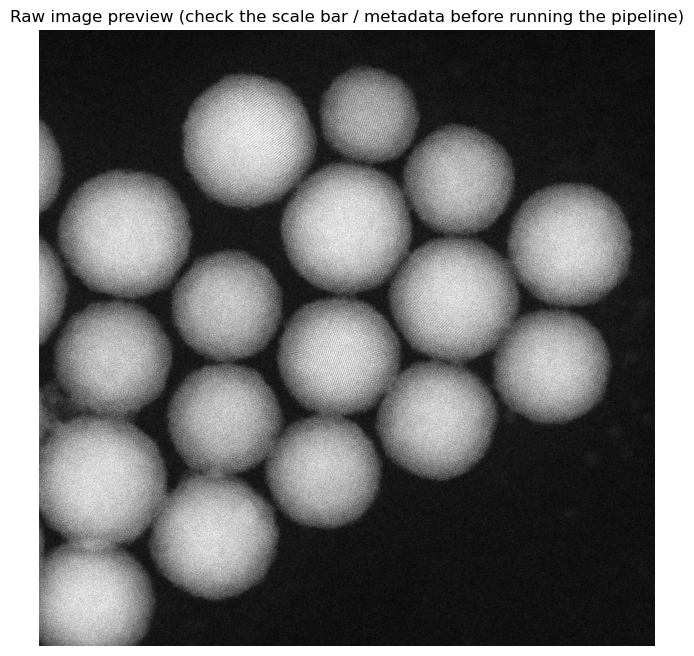

nm/px: 0.0395, dark-field: True, calibration source: metadata


In [6]:
preview_gray, preview_nm_per_px, preview_is_darkfield, preview_calib = load_image(
    image_path, scalebar_nm=nm, scalebar_region=scalebar_region,
)

plt.figure(figsize=(8, 8))
plt.imshow(preview_gray, cmap="gray")
plt.title("Raw image preview (check the scale bar / metadata before running the pipeline)")
plt.axis("off")
plt.show()

print("nm/px: " + format(preview_nm_per_px, ".4f") + ", dark-field: " + str(preview_is_darkfield) +
      ", calibration source: " + preview_calib["source"])

## 2-3. Segmentation (Otsu) + splitting touching particles (watershed)

In [7]:
def segment_and_split_particles(gray_img, exclude_region=None, min_peak_distance=15, bright_particles=False):
    """
    Segments particles on a uniform background and splits touching
    particles using watershed based on the distance transform.

    Parameters
    ----------
    gray_img : np.ndarray (2D, uint8)
    exclude_region : tuple(float, float, float, float), optional
        Region (row_start, row_end, col_start, col_end), in fractions, to
        exclude from segmentation (e.g. where the scale bar/text is
        located), set to background color before thresholding.
    min_peak_distance : int
        Minimum distance (in pixels) between local maxima of the distance
        transform, used as markers for the watershed. Should be chosen
        based on the approximate particle radius (smaller if particles are
        small/closely packed).
    bright_particles : bool
        False (default) for bright-field-style images where particles are
        darker than the background. True for dark-field/HAADF STEM images,
        where particles are the brightest pixels (Z-contrast).

    Returns
    -------
    labels_ws : np.ndarray (2D, int) - watershed labels (0 = background)
    mask : np.ndarray (2D, bool) - binary mask of the particles
    """
    h, w = gray_img.shape
    work = gray_img.copy()

    if exclude_region is not None:
        r0, r1, c0, c1 = exclude_region
        r0, r1 = int(h * r0), int(h * r1)
        c0, c1 = int(w * c0), int(w * c1)
        background_value = 0 if bright_particles else 255
        work[r0:r1, c0:c1] = background_value  # force to background

    blur = cv2.GaussianBlur(work, (5, 5), 0)
    thresh_type = cv2.THRESH_BINARY if bright_particles else cv2.THRESH_BINARY_INV
    _, th = cv2.threshold(blur, 0, 255, thresh_type + cv2.THRESH_OTSU)

    kernel = np.ones((3, 3), np.uint8)
    th_clean = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel, iterations=1)
    th_clean = cv2.morphologyEx(th_clean, cv2.MORPH_CLOSE, kernel, iterations=1)
    mask = th_clean > 0

    dist = ndi.distance_transform_edt(mask)
    coords = peak_local_max(dist, min_distance=min_peak_distance, labels=mask,
                             exclude_border=False)
    markers_mask = np.zeros(dist.shape, dtype=bool)
    markers_mask[tuple(coords.T)] = True
    markers, _ = ndi.label(markers_mask)

    labels_ws = watershed(-dist, markers, mask=mask)
    return labels_ws, mask

## 4. Particle measurement + noise filtering

In [8]:
def measure_particles(labels_ws, nm_per_px, min_diam_px=25, min_circularity=0.5):
    """
    Computes area, equivalent diameter and circularity for each watershed
    region and filters out regions that are too small or not circular
    enough (typically noise fragments or edge artifacts).

    Returns
    -------
    list of dict, one per accepted particle, with keys:
        label, area_px, eq_diam_px, eq_diam_nm, circularity, solidity, centroid
    """
    props = regionprops(labels_ws)
    particles = []
    for p in props:
        area = p.area
        perim = p.perimeter if p.perimeter > 0 else 1
        circularity = 4 * np.pi * area / (perim ** 2)
        eq_diam_px = 2 * np.sqrt(area / np.pi)

        if eq_diam_px < min_diam_px:
            continue
        if circularity < min_circularity:
            continue

        particles.append({
            "label": p.label,
            "area_px": area,
            "eq_diam_px": eq_diam_px,
            "eq_diam_nm": eq_diam_px * nm_per_px,
            "circularity": circularity,
            "solidity": p.solidity,
            "centroid": p.centroid,  # (row, col)
        })
    return particles

## Polydispersity statistics

In [9]:
def polydispersity_stats(diam_nm):
    """
    Computes polydispersity statistics from an array of diameters (in nm).

    PDI here is defined as (sigma/mean)^2, the same convention typically
    used in DLS. It is a dimensionless metric: lower values indicate a
    more monodisperse sample (e.g. PDI < 0.05 - 0.1 in TEM).
    """
    diam_nm = np.asarray(diam_nm)
    mean_d = diam_nm.mean()
    std_d = diam_nm.std(ddof=1)
    return {
        "n": len(diam_nm),
        "mean_nm": mean_d,
        "median_nm": float(np.median(diam_nm)),
        "std_nm": std_d,
        "cv_percent": std_d / mean_d * 100,
        "pdi": (std_d / mean_d) ** 2,
        "min_nm": float(diam_nm.min()),
        "max_nm": float(diam_nm.max()),
    }

## Visualization

In [10]:
def draw_overlay(color_img, particles, out_path=None):
    overlay = color_img.copy()
    for p in particles:
        cy, cx = p["centroid"]
        r = p["eq_diam_px"] / 2
        cv2.circle(overlay, (int(round(cx)), int(round(cy))), int(round(r)),
                   (0, 0, 255), 2)
        cv2.circle(overlay, (int(round(cx)), int(round(cy))), 1, (0, 255, 0), 2)
    if out_path:
        cv2.imwrite(out_path, overlay)
    return overlay


def show_overlay(overlay_bgr, n_particles=None):
    """Displays a BGR (OpenCV) overlay image inline using matplotlib."""
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB))
    title = "Detected particles"
    if n_particles is not None:
        title += f" (N={n_particles})"
    plt.title(title)
    plt.axis("off")
    plt.show()


def show_calibration_check(gray_img, calib):
    """
    Displays a calibration summary. For images calibrated from a scale
    bar, draws a rectangle over the automatically detected bar. For .emd
    files (metadata-based calibration) there is no bar to draw, so this
    just shows the detector name and nm/px instead.
    """
    color_img = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2BGR)

    if calib.get("bar_bbox"):
        row, col_start, col_end = calib["bar_bbox"]
        pad = 5
        cv2.rectangle(color_img, (col_start, row - pad), (col_end, row + pad), (0, 255, 255), 2)
        title = (
            f"Detected scale bar: {calib['bar_length_px']:.1f} px -> "
            f"{calib['nm_per_px']:.4f} nm/px"
        )
    else:
        detector = calib.get("detector") or "unknown detector"
        title = f"Calibration from metadata ({detector}): {calib['nm_per_px']:.4f} nm/px"

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


def plot_histogram(diam_nm, stats, out_path=None, material="nanoparticles"):
    plt.figure(figsize=(7, 5))
    plt.hist(diam_nm, bins=30, color="#4C72B0", edgecolor="white")
    plt.axvline(stats["mean_nm"], color="crimson", linestyle="--", linewidth=1.5,
                label=f'Mean = {stats["mean_nm"]:.2f} nm')
    plt.xlabel("Particle diameter (nm)")
    plt.ylabel("Count")
    plt.title(
        f'Size distribution {material} (N={stats["n"]})\n'
        f'Std dev = {stats["std_nm"]:.2f} nm, CV = {stats["cv_percent"]:.1f}%, '
        f'PDI = {stats["pdi"]:.4f}'
    )
    plt.legend()
    plt.tight_layout()
    if out_path:
        plt.savefig(out_path, dpi=150)
    plt.show()

## Full pipeline

In [11]:
def analyze_image(image_path, scalebar_nm=None,
                   scalebar_region=(0.85, 1.0, 0.0, 0.35),
                   min_peak_distance=15, min_diam_px=25, min_circularity=0.5,
                   material="nanoparticles", outdir=None, emd_signal_index=0):
    """
    Runs the entire pipeline on a TEM/STEM image -- either a regular image
    file with a scale bar (jpg/png/tif/...) or a Thermo Fisher .emd file
    (calibration and bright-/dark-field mode read from its metadata) --
    and returns calibration, particle list, statistics, the grayscale
    image and the overlay image (BGR). If outdir is specified, also saves
    overlay.png and histogram.png.
    """
    gray, nm_per_px, is_darkfield, calib = load_image(
        image_path, scalebar_nm=scalebar_nm, scalebar_region=scalebar_region,
        emd_signal_index=emd_signal_index,
    )

    exclude_region = scalebar_region if calib["source"] == "scalebar" else None

    labels_ws, mask = segment_and_split_particles(
        gray, exclude_region=exclude_region, min_peak_distance=min_peak_distance,
        bright_particles=is_darkfield,
    )

    particles = measure_particles(
        labels_ws, nm_per_px=nm_per_px,
        min_diam_px=min_diam_px, min_circularity=min_circularity,
    )
    diam_nm = np.array([p["eq_diam_nm"] for p in particles])
    stats = polydispersity_stats(diam_nm)

    if outdir:
        os.makedirs(outdir, exist_ok=True)

    color_img = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    overlay_path = os.path.join(outdir, "overlay.png") if outdir else None
    overlay = draw_overlay(color_img, particles, overlay_path)

    result = {
        "calibration": calib,
        "particles": particles,
        "stats": stats,
        "overlay": overlay,
        "gray": gray,
        "is_darkfield": is_darkfield,
    }

    if outdir:
        plot_histogram(diam_nm, stats, os.path.join(outdir, "histogram.png"),
                        material=material)

    return result

## Run pipeline

Uses the `image_path` and parameters set in the **Configuration** cell above. Displays, in order: the scale bar calibration check (yellow box = detected bar), the size-distribution histogram, and the detected-particles overlay (red circles = diameter, green dot = centroid).

In [12]:
result = analyze_image(
    image_path,
    scalebar_nm=nm,
    scalebar_region=scalebar_region,
    outdir=outdir,
)

show_calibration_check(result["gray"], result["calibration"])
show_overlay(result["overlay"], n_particles=result["stats"]["n"])

result["stats"]

C:\Users\agriesi\AppData\Local\Temp\ipykernel_17316\1249230804.py:10: RuntimeWarning: Mean of empty slice.
  mean_d = diam_nm.mean()
C:\Users\agriesi\AppData\Local\hyperspy-bundle\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\agriesi\AppData\Local\hyperspy-bundle\Lib\site-packages\numpy\core\_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\agriesi\AppData\Local\hyperspy-bundle\Lib\site-packages\numpy\core\_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\agriesi\AppData\Local\hyperspy-bundle\Lib\site-packages\numpy\core\_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\agriesi\AppData\Local\hyperspy-bundle\Lib\site-packages\numpy\core\fromnumeric

ValueError: zero-size array to reduction operation minimum which has no identity

## Batch processing (multiple images)

Run the full pipeline on every image inside a folder and collect one summary row per image, plus a pooled size distribution across the whole batch.

**Assumption**: all *non-`.emd`* images in the folder share the same scale bar value (`nm`, set in Configuration). `.emd` files are calibrated individually from their own metadata, so you can freely mix `.emd` and scale-bar images (or run different-scalebar groups separately) in the same folder.

In [ ]:
import glob
import pandas as pd


def analyze_folder(folder_path, scalebar_nm=None, scalebar_region=(0.85, 1.0, 0.0, 0.35),
                    min_peak_distance=15, min_diam_px=25, min_circularity=0.5,
                    material="nanoparticles", outdir=None, show_plots=False,
                    extensions=(".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".emd")):
    """
    Runs analyze_image() on every image found directly inside
    folder_path (non-recursive) and returns a dict {image_name: result}.
    Images that fail (e.g. scale bar not found) are skipped with a
    printed warning instead of stopping the whole batch.

    scalebar_nm is only used for non-.emd images -- .emd files are
    calibrated from their own metadata regardless of this value, so a
    folder can freely mix .emd files with scale-bar images.

    If outdir is given, per-image outputs are saved under
    outdir/<image_name>/ (overlay.png, histogram.png).
    """
    image_paths = sorted(
        p for p in glob.glob(os.path.join(folder_path, "*"))
        if os.path.splitext(p)[1].lower() in extensions
    )
    if not image_paths:
        raise FileNotFoundError("No images found in: " + folder_path)

    results = {}
    for img_path in image_paths:
        name = os.path.splitext(os.path.basename(img_path))[0]
        img_outdir = os.path.join(outdir, name) if outdir else None
        try:
            res = analyze_image(
                img_path, scalebar_nm=scalebar_nm, scalebar_region=scalebar_region,
                min_peak_distance=min_peak_distance, min_diam_px=min_diam_px,
                min_circularity=min_circularity, material=material, outdir=img_outdir,
            )
        except Exception as exc:
            print("[SKIPPED] " + name + ": " + str(exc))
            continue

        results[name] = res
        s = res["stats"]
        print(name + ": N=" + str(s["n"]) + ", mean=" + format(s["mean_nm"], ".2f") +
              " nm, CV=" + format(s["cv_percent"], ".1f") + "%, PDI=" + format(s["pdi"], ".4f"))

        if show_plots:
            show_calibration_check(res["gray"], res["calibration"])
            show_overlay(res["overlay"], n_particles=s["n"])

    return results


def summarize_folder_results(results):
    """Builds a one-row-per-image summary table from analyze_folder() output."""
    rows = []
    for name, res in results.items():
        row = {"image": name}
        row.update(res["stats"])
        rows.append(row)
    return pd.DataFrame(rows).set_index("image").sort_index()

### Run batch analysis

Set `images_folder` to the folder containing all your TEM images, then run:

In [ ]:
images_folder = "./Data"  # <-- folder containing all your TEM images

folder_results = analyze_folder(
    images_folder,
    scalebar_nm=nm,
    scalebar_region=scalebar_region,
    outdir=outdir,
    show_plots=True,  # set to False to skip the per-image calibration check + overlay for large batches
)

summary = summarize_folder_results(folder_results)
summary

### Combined size distribution (all images pooled)

In [ ]:
all_diam_nm = np.concatenate([
    np.array([p["eq_diam_nm"] for p in res["particles"]])
    for res in folder_results.values()
])
combined_stats = polydispersity_stats(all_diam_nm)
plot_histogram(
    all_diam_nm, combined_stats,
    out_path=os.path.join(outdir, "combined_histogram.png") if outdir else None,
)
combined_stats